In [125]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [126]:
# 다항회귀로 구현하시오 

df = pd.read_excel('data/study.xlsx', header=1)
# df.columns  
# df.head()    

# df.columns = ['hour', 'score']
# df = df[df['hour'] != 'hour'].reset_index(drop=True)
df

,hour,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22
5,3.2,30
6,3.9,42
7,4.4,48
8,4.5,38
9,5.0,58


In [127]:
# data = df.iloc[:, 0].values
# label = df.iloc[:, 1:].values
# data
# label

data = df.iloc[:, 0].values
label = df.iloc[:, 1].values


In [128]:
data = data.reshape(-1, 1)
label = label.reshape(-1, 1)
data
label

array([[ 10],
       [  8],
       [ 14],
       [ 26],
       [ 22],
       [ 30],
       [ 42],
       [ 48],
       [ 38],
       [ 58],
       [ 60],
       [ 72],
       [ 62],
       [ 68],
       [ 72],
       [ 58],
       [ 76],
       [ 86],
       [ 90],
       [100]])

In [141]:
train_data,test_data,train_label,test_label = train_test_split(data,label)
# train_data
# test_data

train_label

array([[ 68],
       [ 58],
       [ 60],
       [ 58],
       [ 76],
       [ 86],
       [ 72],
       [ 26],
       [100],
       [ 38],
       [ 72],
       [ 90],
       [ 42],
       [ 62],
       [ 22]])

In [142]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
# train_data
# test_data

train_label

array([[ 68],
       [ 58],
       [ 60],
       [ 58],
       [ 76],
       [ 86],
       [ 72],
       [ 26],
       [100],
       [ 38],
       [ 72],
       [ 90],
       [ 42],
       [ 62],
       [ 22]])

In [143]:
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))
test_poly


array([[10.24,  3.2 ],
       [19.36,  4.4 ],
       [ 0.25,  0.5 ],
       [ 1.44,  1.2 ],
       [ 3.24,  1.8 ]])

In [144]:
lr = LinearRegression() 
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
print('예측 : ',predict)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('학습데이터 예측 : ',score)
print('테스트데이터 예측 : ',score2)

예측 :  [[32.87395607]
 [47.08330348]
 [-3.06276484]
 [ 6.78141494]
 [14.92552856]]
학습데이터 예측 :  0.9262329577018449
테스트데이터 예측 :  0.8408414913416298


In [145]:
print(lr.coef_,lr.intercept_)

[[-0.37660867 14.7033487 ]] [-10.32028702]


In [146]:
in_data = input('공부시간을 입력하세요.>> ')
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]])
print(f"공부시간에 따른 예측점수 : {result[0][0]:.2f} 점")

공부시간에 따른 예측점수 : 74.15 점


In [148]:
# 구간별 직선을 그리기 위해 범위 정수배열 생성
point = np.arange(1,10)
point

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [149]:
# lr.coef_ : 다항회귀는 기울기가 2개 나옴, lr.intercept_ : y절편 
print(lr.coef_, lr.intercept_)

[[-0.37660867 14.7033487 ]] [-10.32028702]


train_label 모양: (15, 1)
(2,) (9,)


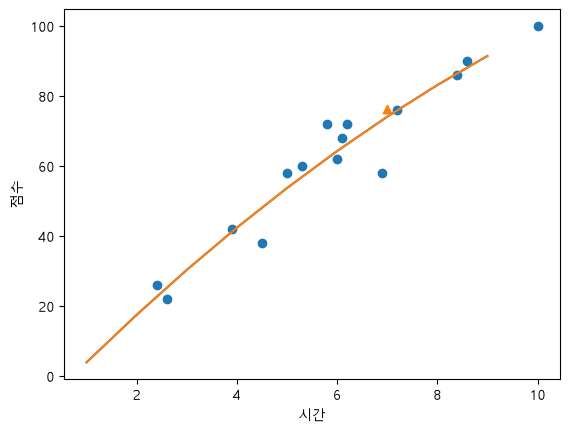

In [ ]:
print("train_label 모양:", train_label.shape)
# train_label 모양: (15, 1): 
# 15 뒤에 , 1이 붙어 있는 것이 train_label이 2차원(상자 2겹) 상태라는 뜻
# train_label까지 2차원으로 바꿨기 때문에 lr.coef_가 2중 상자([[a, b]])로 만들어진 것

# 산점도 그래프
plt.scatter(train_data, train_label)
plt.scatter(7, 76.30, marker='^')
print(lr.coef_[0].shape, point.shape)
plt.plot(point, lr.coef_[0][0]*point**2 + lr.coef_[0][1]*point + lr.intercept_[0])
plt.plot(point, lr.coef_[0,0]*point**2 + lr.coef_[0,1]*point + lr.intercept_[0])

plt.xlabel('시간')
plt.ylabel('점수')
plt.show()

# plt.scatter(train_data, train_label)
# plt.scatter(8, 85.72, marker='^')
# # plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
# plt.plot(point, lr.coef_[0][0]*point**2 + lr.coef_[0][1]*point + lr.intercept_[0])
# plt.xlabel('시간')
# plt.ylabel('점수')
# plt.show()